# From slicer to G-code: simulating the print

This notebook covers the last stage of S4 Slicer, and ends with an animation of the part being printed layer by layer.

How the G-code gets made:
1. `main.ipynb` bends the part so its overhangs become printable, and saves the bent shape as an STL.
2. **Cura** slices that bent part into ordinary flat layers and writes G-code: `input_gcode/<model>_deformed_tet.gcode`.
3. `main.ipynb` carries every point of that G-code back into the original, unbent part. The flat layers become curved ones. It also works out how far to tilt the nozzle at each point, then writes G-code for S4's 4-axis printer: `output_gcode/<model>.gcode`.

This notebook reads both G-code files, explains what's in them, turns the printer's commands back into nozzle positions, and simulates the print.

Run `main.ipynb` all the way through first. If you pair a freshly bent mesh with the sample Cura G-code that comes with the repo, some points get lost (`main.ipynb` warns about this) and the print will show gaps. Slice your own STL for a clean result.

## 0. Setup

In [1]:
import os
import re
import imageio.v3 as iio
import numpy as np
import matplotlib.pyplot as plt
import pyvista as pv
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Same switch as main.ipynb: True gives rotatable 3D views, False gives static images
INTERACTIVE_PLOTS = True
if INTERACTIVE_PLOTS:
    try:
        pv.set_jupyter_backend('trame')
    except ImportError as e:
        print(f'Interactive plots unavailable ({e}). Falling back to static images.')
        pv.set_jupyter_backend('static')
else:
    pv.set_jupyter_backend('static')

def set_view(plotter):
    # one camera angle for every 3D view: from the front, a little to the side and above
    plotter.camera_position = "xz"
    plotter.camera.azimuth = 25
    plotter.camera.elevation = 20

model_name = "pi 3mm"
NOZZLE_OFFSET = 42   # mm from the tilt pivot to the nozzle tip; must match NOZZLE_OFFSET in main.ipynb

cura_path = os.path.join("..", "input_gcode", f"{model_name}_deformed_tet.gcode")
s4_path = os.path.join("..", "output_gcode", f"{model_name}.gcode")
part_path = os.path.join("..", "input_models", f"{model_name}.stl")
for path in (cura_path, s4_path, part_path):
    print(os.path.abspath(path), "found" if os.path.isfile(path) else "NOT FOUND")

word = re.compile(r"([A-Z])(-?\d*\.?\d+)")    # one G-code word, e.g. X12.5 -> ("X", "12.5")

c:\Users\jackt\Downloads\S4_Slicer-main\S4_Slicer-main\input_gcode\pi 3mm_deformed_tet.gcode found
c:\Users\jackt\Downloads\S4_Slicer-main\S4_Slicer-main\output_gcode\pi 3mm.gcode found
c:\Users\jackt\Downloads\S4_Slicer-main\S4_Slicer-main\input_models\pi 3mm.stl found


## 1. Cura's G-code: flat layers

G-code is a list of commands for the printer, one per line. Cura's file uses a handful of them:

| Command | Meaning |
|---|---|
| `G0` | Travel: move without printing |
| `G1` | Print move: move while pushing out filament |
| `X`, `Y`, `Z` | Where to move to (mm) |
| `E` | How much filament to push (mm). Negative values pull it back (a *retraction*), which stops it oozing during travel moves |
| `F` | Speed (mm/min) |
| `;LAYER:n` | A comment marking the start of layer `n` |

Here's the start of the first layer:

In [2]:
with open(cura_path, encoding="utf-8", errors="replace") as fh:
    cura_lines = fh.readlines()

header = {line.split(":")[0]: line.split(":", 1)[1].strip() for line in cura_lines[:1100] if line.startswith((";Layer height", ";LAYER_COUNT", ";TIME:"))}
print(header, "\n")
first_layer = next(i for i, line in enumerate(cura_lines) if line.startswith(";LAYER:0"))
print("".join(cura_lines[first_layer:first_layer + 12]))

{';TIME': '1108', ';Layer height': '0.13', ';LAYER_COUNT': '206'} 

;LAYER:0
;note -- min layer time used
M106 S255
;MESH:pi 3mm_deformed_tet.stl
G0 F9600 X-7.358 Y2.025 Z0.3
;TYPE:WALL-OUTER
G1 F3600 E1
G1 F392.4 X-7.47 Y1.588 E0.03871
G1 X-8.04 Y-.112 E0.15386
G1 F414.1 X-7.946 Y-1.237 E0.0918
G1 F480.4 X-7.796 Y-2.646 E0.09932
G1 F533.6 X-7.358 Y-3.389 E0.05443



Read the print moves and note which layer each one belongs to. Cura's start code runs in absolute extrusion mode (`M82`) and only switches to relative mode (`M83`) just before layer 0. Moves before `;LAYER:0` are skipped, so only real layers get counted.

In [3]:
cura_starts, cura_ends, cura_layer = [], [], []
position = np.zeros(3)
layer = -1
for line in cura_lines:
    if line.startswith(";LAYER:"):
        layer = int(line[len(";LAYER:"):])
        continue
    code = line.split(";")[0].strip()
    if not code:
        continue
    command, *rest = code.split()
    if command not in ("G0", "G1"):
        continue
    values = {letter: float(number) for letter, number in word.findall(" ".join(rest))}
    new_position = position.copy()
    for axis, letter in enumerate("XYZ"):
        if letter in values:
            new_position[axis] = values[letter]
    if command == "G1" and values.get("E", 0) > 0 and layer >= 0 and np.any(new_position != position):
        cura_starts.append(position)
        cura_ends.append(new_position)
        cura_layer.append(layer)
    position = new_position

cura_layer = np.array(cura_layer)
print(f"{len(cura_layer)} print moves across {len(np.unique(cura_layer))} layers that contain printing")

29317 print moves across 205 layers that contain printing


In [4]:
def segments(starts, ends):
    # a PyVista mesh of straight lines, one from each start point to its end point
    points = np.empty((2 * len(starts), 3))
    points[0::2] = starts
    points[1::2] = ends
    return pv.line_segments_from_points(points)

flat_print = segments(np.array(cura_starts), np.array(cura_ends))
flat_print.cell_data["layer"] = cura_layer

pl = pv.Plotter()
pl.add_mesh(flat_print, scalars="layer", cmap="viridis", line_width=2)
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:51142/index.html?ui=P_0x197be539550_0&reconnect=auto" class="pyvis…

This is the *bent* part, cut into flat layers. Cura doesn't know about the bending: to Cura it's just an odd-looking part.

## 2. What `main.ipynb` does in between

The G-code cells of `main.ipynb` take each point from Cura's file and:

- **Move it back into the original part.** The point is found inside one of the bent tetrahedra. Its position relative to that tetrahedron's 4 corners is kept, and it's placed at the same spot in the unbent tetrahedron. Flat layers come out curved.
- **Work out the nozzle tilt.** Each tetrahedron was rotated by some angle when the part was bent. The tilt at a point is a blend of the rotations around it, so the nozzle stays square to the curved layer.
- **Adjust the extrusion.** Bending stretched or squashed each tetrahedron, so the filament amount is scaled by how much its volume changed (capped at 10×).
- **Smooth the tilt** and add extra points wherever it would change by more than 1° in one step, so the nozzle never swings quickly into the part.
- **Convert to the printer's axes** and correct for the nozzle tip sitting 42 mm from the tilt pivot (next section).

## 3. S4's G-code: four axes

S4's printer doesn't move in X and Y. The **bed spins** and the **print head moves in and out, up and down, and tilts**:

| Letter | Axis |
|---|---|
| `C` | Bed rotation (degrees). It keeps counting past 360° rather than jumping back to 0 |
| `X` | How far the head is from the bed's centre (mm) |
| `Z` | Height (mm) |
| `B` | Nozzle tilt (degrees) |
| `E` | Filament (mm, relative: each move pushes this much more) |
| `F` | Speed. After `G93` it's **inverse time**: the move should take 1/F minutes. After `G94` it's normal mm/min |

Inverse time is used because a move here mixes degrees (C and B) with millimetres (X and Z), so "mm per minute" doesn't mean much. Instead, each move just says how long it should take.

Here are some print moves from the middle of the file:

In [5]:
with open(s4_path, encoding="utf-8") as fh:
    s4_lines = fh.readlines()
middle = len(s4_lines) // 2
print("".join(s4_lines[middle:middle + 8]))

G01 C-25367.93585 X25.29508 Z11.84303 B-16.90122 E0.0064 F40604.3547
G01 C-25369.00424 X25.73827 Z11.69390 B-17.42647 E0.0070 F37080.1155
G01 C-25370.06012 X26.18494 Z11.54141 B-17.95173 E0.0070 F37080.1155
G01 C-25372.17857 X27.04266 Z11.23660 B-18.93792 E0.0140 F18540.0577
G01 C-25373.61368 X27.90785 Z10.92900 B-19.87730 E0.0108 F23951.4394
G01 C-25374.97914 X28.71730 Z10.61947 B-20.72125 E0.0107 F23951.4394
G01 C-25376.29349 X29.47059 Z10.32183 B-21.47457 E0.0107 F23951.4394
G01 C-25377.57291 X30.25053 Z10.01034 B-22.17267 E0.0119 F21659.7380



### Where's the nozzle tip?

`X` and `Z` say where the head's **tilt pivot** is, not where the nozzle tip is. The tip is 42 mm below the pivot, so when the nozzle tilts by B, the tip swings sideways and up:

- tip distance from the centre = X + 42 · sin(B)
- tip height = Z + 42 · (1 − cos(B))

`main.ipynb` works these out backwards when it writes the file. Here they are drawn for a made-up position, seen from the side:

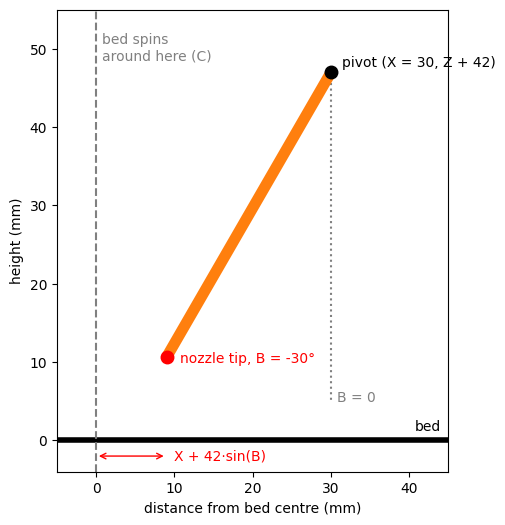

In [6]:
example_X, example_Z, example_B = 30.0, 5.0, -30.0       # a made-up machine position
b = np.radians(example_B)
pivot = np.array([example_X, example_Z + NOZZLE_OFFSET])
tip = pivot + NOZZLE_OFFSET * np.array([np.sin(b), -np.cos(b)])

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([-5, 45], [0, 0], color="black", lw=4)
ax.text(44, 1.2, "bed", ha="right")
ax.axvline(0, color="grey", ls="--")
ax.text(0.8, 52, "bed spins\naround here (C)", color="grey", va="top")
ax.plot([pivot[0], pivot[0]], [pivot[1], pivot[1] - NOZZLE_OFFSET], ":", color="grey")
ax.text(pivot[0] + 0.8, pivot[1] - NOZZLE_OFFSET, "B = 0", color="grey")
ax.plot(*zip(pivot, tip), color="tab:orange", lw=8, solid_capstyle="round")
ax.plot(*pivot, "o", color="black", ms=9)
ax.annotate(f"pivot (X = {example_X:.0f}, Z + 42)", pivot, xytext=(8, 4), textcoords="offset points")
ax.plot(*tip, "o", color="red", ms=9)
ax.annotate(f"nozzle tip, B = {example_B:.0f}°", tip, xytext=(10, -4), textcoords="offset points", color="red")
ax.annotate("", xy=(tip[0], -2), xytext=(0, -2), arrowprops=dict(arrowstyle="<->", color="red"))
ax.text(tip[0] + 1, -2, "X + 42·sin(B)", color="red", va="center")
ax.set_xlim(-5, 45); ax.set_ylim(-4, 55)
ax.set_aspect("equal")
ax.set_xlabel("distance from bed centre (mm)"); ax.set_ylabel("height (mm)")
plt.show()

### Read the file

Each `G0`/`G1` line becomes one row. An axis that isn't mentioned keeps its last value, so the code tracks the machine's position as it reads. It also notes whether each move came after `G93` (inverse time) or `G94` (mm/min).

In [7]:
rows = []
machine = {"C": 0.0, "X": 0.0, "Z": 20.0, "B": 0.0}     # the header's first move goes here
inverse_time = False
for line in s4_lines:
    code = line.split(";")[0].strip()
    if code.startswith("G93"):
        inverse_time = True
        continue
    if code.startswith("G94"):
        inverse_time = False
        continue
    if not code:
        continue
    command, *rest = code.split()
    if command not in ("G0", "G00", "G1", "G01"):
        continue
    values = {letter: float(number) for letter, number in word.findall(" ".join(rest))}
    machine.update({letter: values[letter] for letter in "CXZB" if letter in values})
    rows.append((command in ("G1", "G01"), machine["C"], machine["X"], machine["Z"], machine["B"],
                 values.get("E", 0.0), values.get("F", np.nan), inverse_time))

is_print_command, C, X, Z, B, E, F, inverse_time_mode = np.array(rows).T
print(f"{len(rows)} moves; nozzle tilt B from {B.min():.1f}° to {B.max():.1f}°")

130153 moves; nozzle tilt B from -56.4° to 22.3°


### Turn machine positions back into nozzle-tip positions

This uses the formulas above. On travel moves `main.ipynb` lifts the nozzle 1 mm (a *z-hop*) by pretending the nozzle is 1 mm longer and raising Z by 1 mm. Travel starts at a retraction (`E-1.0`) and ends at the matching un-retraction (`E1.0`), so the same rule is followed here to undo the z-hop.

Two moves at the very start push filament through the nozzle to prime it: one from `main.ipynb`'s header, and one from Cura's start code that `main.ipynb` carried over. Neither is part of the part, so print moves are only counted from the first un-retraction onwards.

In [8]:
travelling = np.zeros(len(E), dtype=bool)
state = False
for i, e in enumerate(E):
    if e == -1.0:
        state = True          # retraction: a travel move starts
    elif e == 1.0:
        state = False         # un-retraction: printing again
    travelling[i] = state
z_hop = travelling.astype(float)

b = np.radians(B)
tip_r = X + np.sin(b) * (NOZZLE_OFFSET + z_hop)
tip_z = Z - (np.cos(b) - 1) * (NOZZLE_OFFSET + z_hop) - z_hop
theta = np.radians(C)
tip = np.column_stack((tip_r * np.cos(theta), tip_r * np.sin(theta), tip_z))

started = np.cumsum(E == 1.0) > 0                   # from the first un-retraction onwards
printing = (is_print_command == 1) & (E > 0) & (E != 1.0) & started
print(f"{printing.sum()} print moves")
print("tip positions span", np.round(tip[printing].min(axis=0), 1), "to", np.round(tip[printing].max(axis=0), 1))

103488 print moves
tip positions span [-24.7  -5.2   0. ] to [25.1  5.1 20. ]


That range should match the original part's size, which is centred on the bed with its bottom at z = 0, as in `main.ipynb`:

In [9]:
part = pv.read(part_path)
x_min, x_max, y_min, y_max, z_min, z_max = part.bounds
part.points -= np.array([(x_min + x_max) / 2, (y_min + y_max) / 2, z_min])
print("part spans          ", np.round(np.array(part.bounds[0::2]), 1), "to", np.round(np.array(part.bounds[1::2]), 1))

part spans           [-25.  -5.   0.] to [25.  5. 20.]


### How long it takes

After `G93` each move takes 1/F minutes. The few moves after `G94` are retractions and the priming moves. Those are timed by their length at F mm/min. This ignores acceleration, so a real print takes somewhat longer.

In [10]:
step_length = np.linalg.norm(np.diff(tip, axis=0, prepend=tip[:1]), axis=1)
minutes = np.where(inverse_time_mode == 1, 1 / F, step_length / F)
minutes = np.nan_to_num(minutes)                     # moves with no F at all (the header) take no time here
elapsed = np.cumsum(minutes)
print(f"estimated print time: {elapsed[-1]:.1f} minutes")

estimated print time: 12.0 minutes


## 4. The finished print

Every print move drawn as a line, coloured by how far the nozzle was tilted when it was laid down. The layers now follow the curve of the part, and the nozzle tilts most where the bar overhangs.

In [11]:
previous = np.flatnonzero(printing) - 1               # each print move starts where the move before it ended
curved_print = segments(tip[previous], tip[printing])
curved_print.cell_data["nozzle tilt B (°)"] = B[printing]
tilt_limit = np.abs(B[printing]).max()

pl = pv.Plotter()
pl.add_mesh(curved_print, scalars="nozzle tilt B (°)", cmap="coolwarm", clim=[-tilt_limit, tilt_limit], line_width=2)
set_view(pl)
pl.show()

Widget(value='<iframe src="http://localhost:51142/index.html?ui=P_0x197d7fa3c50_1&reconnect=auto" class="pyvis…

### Checking for gaps

Print moves are normally short, because `main.ipynb` cuts every move into pieces of at most 0.6 mm before un-bending them. A print move much longer than that jumps across a gap. The points in between were lost because they fell outside the mesh; `main.ipynb` reports how many as `Lost N vertices`. The printer really would extrude along a jump like that, so each one shows up as a streak in the picture above. With G-code sliced from your own STL there should be few or none.

In [12]:
move_length = np.linalg.norm(tip[printing] - tip[previous], axis=1)
long_moves = move_length > 3
print(f"typical print move: {np.median(move_length):.2f} mm")
print(f"{long_moves.sum()} print moves longer than 3 mm ({100 * long_moves.mean():.2f}%), the longest {move_length.max():.1f} mm")

typical print move: 0.39 mm
337 print moves longer than 3 mm (0.33%), the longest 9.6 mm


## 5. Print simulation

The animation steps through the print at even intervals of print time, so slow sections take more frames than fast ones. Each frame shows:
- everything printed so far, coloured by nozzle tilt as above,
- what was printed since the last frame, in yellow: the current layer being laid down,
- the nozzle at its current position, tilted by B,
- the finished part, drawn faintly for reference.

On the real machine the bed spins underneath the head. Here the part stays still and the nozzle moves around it, which is the same motion seen from the part's point of view. Rendering takes about 10 seconds.

The frames are also saved as a GIF in this folder (`<model>_print_simulation.gif`), so you can open or share the animation outside Jupyter.

In [ ]:
def nozzle(position, tilt_degrees, bed_angle_degrees):
    # a cone for the nozzle and a cylinder for the heater block, tilted the same way as on the printer
    t, c = np.radians(tilt_degrees), np.radians(bed_angle_degrees)
    outward = np.array([np.cos(c), np.sin(c), 0])
    up_the_nozzle = -np.sin(t) * outward + np.cos(t) * np.array([0, 0, 1])
    tip_cone = pv.Cone(center=position + 2 * up_the_nozzle, direction=-up_the_nozzle, height=4, radius=1.5, resolution=60)
    block = pv.Cylinder(center=position + 8 * up_the_nozzle, direction=up_the_nozzle, radius=3, height=8, resolution=60)
    return tip_cone + block

def studio_backdrop(size=64):
    # Chrome is a mirror, so it needs surroundings to reflect: a bright sky, a dark band at the horizon
    # and a grey floor, built as the 6 faces of a cube
    height = np.linspace(1, -1, size)[:, None] * np.ones((1, size))      # +1 at the top of a side face, -1 at the bottom
    side = np.where(height > 0.1, 0.55 + 0.45 * height, np.where(height > -0.15, 0.06, 0.4))
    faces = [side, side, np.ones((size, size)), np.full((size, size), 0.4), side, side]
    return pv.Texture([pv.Texture(np.dstack([(face * 255).astype(np.uint8)] * 3)).to_image() for face in faces])

chrome = dict(color="#f5f5f7", pbr=True, metallic=1.0, roughness=0.12, smooth_shading=True, split_sharp_edges=True)

print_index = np.flatnonzero(printing)
print_starts, print_ends = tip[print_index - 1], tip[print_index]
print_times = elapsed[print_index]

frame_times = np.linspace(0, elapsed[-1], 80)
pl = pv.Plotter(off_screen=True, window_size=(800, 520))
pl.set_environment_texture(studio_backdrop())        # only the chrome nozzle reflects it; everything else is unchanged
pl.renderer.SetEnvironmentUp(0, 0, 1)
pl.renderer.SetEnvironmentRight(1, 0, 0)
pl.add_mesh(part, color="lightgrey", opacity=0.08)
set_view(pl)
pl.camera.zoom(1.1)
frames = []
previous_time = 0.0
for now in list(frame_times) + [frame_times[-1]] * 8:    # repeat the last frame so it pauses at the end
    done = print_times <= now
    new = done & (print_times > previous_time)
    actors = []
    if done.any():
        laid = segments(print_starts[done], print_ends[done])
        laid.cell_data["tilt"] = B[print_index[done]]
        actors.append(pl.add_mesh(laid, scalars="tilt", cmap="coolwarm", clim=[-tilt_limit, tilt_limit], line_width=2, show_scalar_bar=False))
    if new.any():
        actors.append(pl.add_mesh(segments(print_starts[new], print_ends[new]), color="yellow", line_width=4))
    current = min(np.searchsorted(elapsed, now), len(elapsed) - 1)
    head = nozzle(tip[current], B[current], C[current])
    actors.append(pl.add_mesh(head, **chrome))
    actors.append(pl.add_silhouette(head, color="grey", line_width=1))   # a thin outline so the bright chrome stands out from the white background
    pl.renderer.ResetCameraClippingRange()           # otherwise the nozzle is cut off when it rises above the part
    pl.add_text(f"{now:5.1f} of {elapsed[-1]:.1f} min    nozzle tilt {B[current]:+5.1f}°", name="label", font_size=12)
    frames.append(pl.screenshot(return_img=True))
    for actor in actors:
        pl.remove_actor(actor)
    previous_time = now
pl.close()

gif_path = f"{model_name}_print_simulation.gif"
iio.imwrite(gif_path, frames, duration=125, loop=0)     # 125 ms a frame = 8 frames a second, looping forever
print("saved", os.path.abspath(gif_path))

fig = plt.figure(figsize=(8, 5.2), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.axis("off")
image = ax.imshow(frames[0])
anim = FuncAnimation(fig, lambda i: image.set_data(frames[i]), frames=len(frames))
plt.close(fig)   # stop Jupyter also showing the last frame as a still image
with plt.rc_context({"animation.frame_format": "jpeg"}):   # jpeg frames keep the notebook small
    player = anim.to_jshtml(fps=8, default_mode="once")
HTML(player)

## Summary

- Cura slices the **bent** part into flat layers and writes ordinary G-code (`G0`/`G1`, `X Y Z E F`).
- `main.ipynb` carries every point back into the original part, so flat layers become curved. It also adds a nozzle tilt, scales the extrusion, and writes G-code for the 4-axis printer: `C` (bed rotation), `X` (distance from the centre), `Z` (height) and `B` (tilt), with `G93` inverse-time speeds.
- `X` and `Z` place the tilt pivot, not the nozzle tip. The tip is found with tip distance = X + 42·sin(B) and tip height = Z + 42·(1 − cos(B)), plus a 1 mm z-hop on travel moves.
- Played back in time order, the print builds up one curved layer at a time, with the nozzle tilting to stay square to each layer.